In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル・開発環境で実行中。リポジトリルート:", repo_root)


💻 ローカル・開発環境で実行中。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 6.2 USBホストドライバ (`USB 3.0 & xHCI Architecture`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/6/6.2_USB_3_0_xHCI_Architecture.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.10%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20USB%203.0%20xHCI-orange.svg)
![Chapter](https://img.shields.io/badge/Chapter-6.2%20(USB%20Host%20Driver)-green.svg)

---

## 📖 節の概要と学習目標

前節（**第6章 6.1節 / `osbook_day06a`**）では、画面の任意の位置に矢印形状のマウスカーソルを描画し、デスクトップ背景・タスクバー・スタートボタンを美しく配置するデスクトップ UI の描画基盤を構築しました。しかし、そこで描画されたマウスカーソルは固定座標 `(200, 100)` に留まる **静止画** に過ぎず、PC に接続された物理マウスをいくら動かしてもカーソルは微動だにしません。

GUI（*Graphical User Interface*）オペレーティングシステムとして真に機能するためには、**「ハードウェア（USBマウス）から送られてくる移動データ（相対座標変位やボタン押下情報）をリアルタイムに受信し、カーソルの描画座標を更新する」** 仕組みが不可欠です。

現代の PC においてマウスやキーボードなどの入力デバイスを統括しているのが **USB（*Universal Serial Bus*）** であり、Intel が策定した最新の標準ホストコントローラ仕様が **xHCI（*eXtensible Host Controller Interface*）** です。

本節（**第6章 6.2節**）では、MikanOS の USB マウスドライバ実装（6.3節・6.4節）の基盤となる **「USB 3.0 および xHCI のアーキテクチャ・ハードウェアメモリ構造・ロックフリーリング同期アルゴリズム」** を、仕様書（xHCI Specification Rev 1.2）の根本理論から徹底的に解説します：

1. **USB規格とホストコントローラの歴史的変遷**: UHCI / OHCI / EHCI のコンパニオンコントローラ構成の苦悩と、xHCI による統一規格の登場動機
2. **USB の論理階層モデルとトポロジー**: ホスト・ルートハブ・デバイス・コンフィギュレーション・インターフェース・エンドポイントのツリー構造と4大転送モード（Control / Interrupt / Bulk / Isochronous）
3. **xHCI の中核メモリ構造**: DCBAA（256エントリポインタ配列）、Device Context / Input Context（Slot Context, Endpoint Context）のビットレイアウト
4. **TRB (Transfer Request Block) のバイナリ構造**: 16バイト固定長のハードウェアパケット構造、Parameter・Status・Control フィールドのビットアライメント
5. **Cycle Bit (PCS/CCS) によるロックフリー同期数理**: Mutex（排他ロック）を一切使わずに 1 ビットの反転と Link TRB (Toggle Cycle) だけで CPU とハードウェア間の安全なリング巡回を実現する数理的証明
6. **ドアベルレジスタ（Doorbell Registers）**: CPU がコントローラのタスクエンジンを叩き起こすトリガーメカニズム


## 1. なぜ USB ホストドライバが必要なのか？（動機・歴史とアーキテクチャの進化）

### 1.1 レガシーI/O（PS/2）からシリアルバス（USB）へのパラダイムシフト
1980年代〜1990年代初頭の PC/AT 互換機では、キーボードやマウスなどの周辺機器は **PS/2 ポート**（Mini-DIN 6ピン）と呼ばれる専用の端子に接続されていました。PS/2 はマザーボード上のキーボードコントローラ（Intel 8042 等）に直結されており、CPU は特定の I/O ポート（`0x60`, `0x64`）に対して `in` / `out` 命令を実行するだけで、極めて単純に1バイト単位のキーストロークやマウスパケットを読み取ることができました。

しかし、PS/2 や RS-232C シリアルポート、IEEE 1284 パラレルポートなどのレガシーインターフェースには、現代のパーソナルコンピュータとして致命的な欠点が存在していました：
- **ポートの乱立とピン数の浪費**: デバイスの種類ごとに全く異なる形状のコネクタと専用コントローラが必要だった。
- **ホットプラグ（活線挿抜）の非対応**: PC の電源投入後にマウスやキーボードを抜き差しすると認識されないか、最悪の場合回路が損傷した。
- **拡張性の限界**: 1つのポートに1台のデバイスしか接続できず、デイジーチェーンやハブによる分岐が不可能だった。

これらの課題を解決し、**「あらゆる周辺機器を単一の統一コネクタで、電源を入れたまま自由に抜き差しでき、ハブで何台でも数珠つなぎにできる」** 万能インターフェースとして1996年に策定されたのが **USB（*Universal Serial Bus*）** です。

---

### 1.2 ホストコントローラの歴史的変遷: UHCI/OHCI/EHCI から xHCI への進化
USB の登場により周辺機器の接続は劇的に便利になりましたが、**OS 開発者にとっては地獄のような複雑化** がもたらされました。その元凶が、USB のバージョンアップに伴って乱立した **ホストコントローラ（Host Controller）規格の分裂** です。

| コントローラ規格 | 正式名称 | 対応USB規格 | 最大転送速度 | 主な採用企業・特徴 | OSドライバ開発の課題 |
|:---|:---|:---:|:---:|:---|:---|
| **UHCI** | *Universal Host Controller Interface* | USB 1.1 | 1.5 Mbps / 12 Mbps | Intel / VIA | ハードウェアが単純で、OS がフレームリストやキューをソフトウェアで細かく管理する必要があった |
| **OHCI** | *Open Host Controller Interface* | USB 1.1 | 1.5 Mbps / 12 Mbps | Compaq / Microsoft / Apple | ハードウェアがインテリジェントで OS の負担は少ないが、UHCI と完全非互換 |
| **EHCI** | *Enhanced Host Controller Interface* | USB 2.0 | 480 Mbps (High-Speed) | 業界標準 (Intel 主導) | High-Speed 専用。低速（1.5M/12M）機器を扱うには UHCI/OHCI との「コンパニオン関係」が必須 |
| **xHCI** | *eXtensible Host Controller Interface* | **USB 3.0〜3.2+** | **5 Gbps〜20 Gbps+** | **業界統一標準** | **USB 1.1 から 3.x までの全速度を単一コントローラで完全統合。仮想化・ロックフリーリング設計** |

> [!WARNING]
> **かつての悪夢: コンパニオンコントローラ（Companion Controller）構成**<br>
> USB 2.0 (EHCI) 時代の PC にマウス（Low-Speed: 1.5Mbps）を差し込むと、EHCI コントローラは自身でその通信を処理できず、チップセット内の補助コントローラ（UHCI または OHCI）に物理ポートの制御権をハンドオーバー（手渡し）していました。<br>
> このため、当時の OS は EHCI ドライバに加えて、チップセットに応じて UHCI ドライバか OHCI ドライバのどちらかも同時に実装・協調動作させなければマウスすら動かせませんでした。

---

### 1.3 xHCI (USB 3.0) による救済と現代の標準化
この複雑怪奇な構成を根本から刷新すべく、Intel が USB 3.0 の策定とともに発表したのが **xHCI（*eXtensible Host Controller Interface*）** です。xHCI の革新的な特徴は以下の通りです：

1. **速度の完全統合**: USB 1.1 (Low-Speed / Full-Speed)、USB 2.0 (High-Speed)、USB 3.0 (SuperSpeed) のすべての通信を単一の xHCI ドライバだけで直接制御可能。
2. **スケーラビリティと仮想化**: 最大 256 台のデバイススロット（Device Slots）をサポートし、ハードウェア仮想化（SR-IOV）に親和性の高いアーキテクチャ。
3. **リングバッファとロックフリー同期**: 後述する **TRB（*Transfer Request Block*）** と **Cycle Bit** 機構により、OS とホストコントローラが排他ロックなしに超高速かつ安全に通信可能。


## 2. USB の論理階層モデルとトポロジー（Topology & Logical Hierarchy）

USB は単純な1対1のポイント・ツー・ポイント通信ではなく、**階層的なツリートポロジー（Tree Topology）** を形成します。

```mermaid
graph TD
    Host["🖥️ USB Host (PC / CPU)"] --> RootHub["🌳 Root Hub (xHCI 内蔵)"]
    RootHub --> Port1["Port 1: USB Mouse"]
    RootHub --> Port2["Port 2: USB Hub (外部ハブ)"]
    RootHub --> Port3["Port 3: USB Keyboard"]
    Port2 --> HubPort1["Hub Port 1: USB Flash Drive"]
    Port2 --> HubPort2["Hub Port 2: USB Audio DAC"]
```

---

### 2.1 デバイスの内部論理構造（階層ディスクリプタ）
USB デバイスは、内部に **デバイス（Device）→ コンフィギュレーション（Configuration）→ インターフェース（Interface）→ エンドポイント（Endpoint）** という4層の論理構造を持っています：

1. **デバイス（Device）**: 物理的な1台の USB 機器（例: 複合キーボード＆トラックボール機器）。ベンダーID（VID）やプロダクトID（PID）を持ちます。
2. **コンフィギュレーション（Configuration）**: デバイスの動作モード（消費電力設定など）。通常は1つのコンフィギュレーションを選択してアクティブにします。
3. **インターフェース（Interface）**: 機能単位の論理デバイス。例えば「キーボード機能」と「マウス機能」を1台に併せ持つコンポジットデバイスでは、2つの独立したインターフェースを持ち、それぞれに異なるドライバが紐づきます。
4. **エンドポイント（Endpoint）**: 通信の最終的な出入り口（データバッファ）。一意の番号（0〜15）と方向（IN: デバイス→ホスト、OUT: ホスト→デバイス）を持ちます。
   - **Endpoint 0**: すべての USB デバイスに必須の双方向制御用エンドポイント（デフォルトコントロールパイプ）。

---

### 2.2 USB の4大転送モード（Transfer Types）
USB は目的の異なる多様な周辺機器を統一的に扱うため、性質の異なる4種類の通信方式を規定しています：

| 転送モード | 方向 | 帯域保証 | 誤り検出・再送 | 用途・具体例 | MikanOS での役割 |
|:---|:---:|:---:|:---:|:---|:---|
| **Control 転送** | 双方向 (EP0) | あり (ベストエフォート) | **あり (CRC + ACK/NAK)** | デバイスの初期化、ディスクリプタ取得、アドレス設定 | **デバイス検出・初期設定で必須** |
| **Interrupt 転送** | 主に IN | **周期保証 (Polling Interval)** | **あり (CRC + ACK/NAK)** | マウスの移動変位、キーボードのキー押下 | **マウス・キーボードの入力取得（主役！）** |
| **Bulk 転送** | IN / OUT | なし (空き帯域最大活用) | **あり (CRC + ACK/NAK)** | USBメモリ、外付けSSD、プリンタ | 大容量ストレージ通信 |
| **Isochronous 転送** | IN / OUT | **帯域保証 (等時性)** | **なし (再送よりリアルタイム重視)** | Webカメラ映像、USBスピーカー/マイク音声 | ストリーミング |


## 3. xHCI (eXtensible Host Controller Interface) の中核メモリ構造

xHCI は、CPU とホストコントローラがメインメモリ上の共有データ構造を通じて協調動作する **DMA（*Direct Memory Access*）型コントローラ** です。CPU は xHCI の MMIO レジスタを頻繁にポーリングする代わりに、あらかじめメモリ上に構築されたテーブルやリングバッファのアドレスを登録し、ハードウェアが自律的にそれを読み書きします。

### 3.1 DCBAA (Device Context Base Address Array)
xHCI の最も基底に位置するデータ構造が **DCBAA（*Device Context Base Address Array*）** です。

```text
DCBAA (64-bit 物理ポインタの配列: 最大 256 エントリ)
┌────────┬──────────────────────────────────────────┐
│ Slot 0 │ Scratchpad Buffer Array への物理ポインタ │ (ハードウェア内部ワーク領域)
├────────┼──────────────────────────────────────────┤
│ Slot 1 │ Device 1 の Device Context への物理ポインタ│ (例: USB マウス)
├────────┼──────────────────────────────────────────┤
│ Slot 2 │ Device 2 の Device Context への物理ポインタ│ (例: USB キーボード)
├────────┼──────────────────────────────────────────┤
│ ...    │ ...                                      │
├────────┼──────────────────────────────────────────┤
│Slot 255│ Device 255 の Device Context 物理ポインタ│
└────────┴──────────────────────────────────────────┘
```

- OS は xHCI の MMIO レジスタ `DCBAAP`（*Device Context Base Address Array Pointer*）に DCBAA の先頭物理アドレスを書き込むことで、コントローラに全デバイスのコンテキストを通知します。
- **Slot ID 0** は特別で、ホストコントローラが内部計算に使用するスクラッチパッドバッファ配列のポインタを配置します。

---

### 3.2 Device Context と Input Context（Slot & Endpoint Context）
各デバイスのスロットには、そのデバイスの状態を完全に記述する **Device Context（デバイスコンテキスト）** が割り当てられます。Device Context は以下の要素で構成されます：

1. **Slot Context（32バイト）**:
   - デバイス全体のメタデータ。デバイス速度（Low/Full/High/SuperSpeed）、親ハブのルートポート番号、有効なエンドポイントの個数（Context Entries）などを保持します。
2. **Endpoint Context 0〜31（各32バイト）**:
   - デバイスが持つ各エンドポイントの通信パラメータ。エンドポイント種別（Control/Interrupt/Bulk/Isoch）、最大パケットサイズ（Max Packet Size）、および **Transfer Ring（転送リング）の先頭デキューポインタ（TR Dequeue Pointer）** を保持します。

> [!NOTE]
> **Device Context vs Input Context**<br>
> - **Device Context**: ホストコントローラがデバイスの状態を出力・保持するメモリ領域（OS は主に読み取り専用）。<br>
> - **Input Context**: OS が `Address Device` や `Configure Endpoint` コマンドを発行する際、「このパラメータでデバイスを設定してください」とコントローラに要求を伝えるための入力用メモリ領域。


## 4. TRB (Transfer Request Block) のバイナリ構造とビットフィールド導出

xHCI における通信命令・転送データ・完了通知・イベントの最小単位は、すべて **TRB（*Transfer Request Block*）** と呼ばれる **16バイト固定長のハードウェア記述子** です。

### 4.1 TRB の 16バイト・4ダブルワード (Dword) バイナリ構造

| Dword | ビット範囲 | フィールド名 | 内容・役割 |
|:---:|:---:|:---|:---|
| **Dword 0** | `[31:0]` | **Parameter [31:0]** | 64ビットバッファポインタの下位32ビット（またはコマンド引数） |
| **Dword 1** | `[31:0]` | **Parameter [63:32]** | 64ビットバッファポインタの上位32ビット |
| **Dword 2** | `[31:0]` | **Status** | 転送バイト数（Transfer Length）、インターラプタターゲット、完了コード等 |
| **Dword 3** | `[0]` | **Cycle Bit (C)** | **Producer Cycle State (PCS)**: この TRB が有効であることを示す 1 ビットフラグ |
| | `[1]` | **Evaluate Next TRB (ENT)** | 次の TRB を連続評価するかどうかのフラグ |
| | `[2..9]` | **Control Flags** | ISP (Interrupt-on-Short-Packet), CH (Chain), IOC (Interrupt On Completion) 等 |
| | `[15:10]` | **TRB Type [5:0]** | **TRB の種別（6ビット）**: Normal(1), Link(6), Enable Slot(9), Event(32..) 等 |
| | `[31:16]` | **Control Specific** | TRB タイプ固有の制御ビット（スロットIDなど） |

```text
TRB 16バイト バイナリメモリ配置:
+0x00: [ Dword 0: Parameter Low (32-bit)                                         ]
+0x04: [ Dword 1: Parameter High (32-bit)                                        ]
+0x08: [ Dword 2: Status (32-bit: Length / Completion Code)                      ]
+0x0C: [ Dword 3: Control Bits [31:16] | Type [15:10] | Flags [9:1] | Cycle [0]  ]
```

---

### 4.2 主要な TRB の分類

1. **Normal TRB (Type 1)**: バルク転送や割り込み転送でデータバッファの物理アドレスとバイト数を指定する最も基本的な TRB。
2. **Link TRB (Type 6)**: リングバッファの末尾に配置され、次のリングセグメント（通常はリングの先頭）のアドレスを指し示す TRB。**Toggle Cycle (TC) ビット** を持ちます。
3. **Command TRBs (Type 9〜23)**: OS からコントローラへの制御命令（`Enable Slot`, `Address Device`, `Configure Endpoint` 等）。
4. **Event TRBs (Type 32〜39)**: コントローラから OS への完了通知（`Transfer Event`, `Command Completion Event`, `Port Status Change Event` 等）。


## 5. リングバッファと Cycle Bit (PCS/CCS) によるロックフリー同期数理

### 5.1 xHCI が規定する3種類のリングバッファ
xHCI では、すべての通信が以下の3種類の円形キュー（Ring Buffer）を通じて行われます：

1. **Command Ring（コマンドリング）**: OS（Producer）→ xHCI（Consumer）。スロットの有効化やデバイス設定など、ホストコントローラ全体への制御コマンドを投入します。
2. **Transfer Ring（転送リング）**: OS（Producer）→ xHCI（Consumer）。各エンドポイントに1対1で存在し、実際のマウス入力要求（Normal TRB）などを投入します。
3. **Event Ring（イベントリング）**: xHCI（Producer）→ OS（Consumer）。コマンドの完了やデータ受信完了、ポート接続などのイベントを OS に通知します。

---

### 5.2 なぜ 1 ビットの Cycle Bit で排他ロック不要の同期が成立するのか？（数理的証明）

一般的なマルチスレッド/プロデューサー・コンシューマーキューでは、リングバッファの `head`（読み取り位置）と `tail`（書き込み位置）を共有メモリ上で同期する必要があり、競合状態（Race Condition）を防ぐためにアトミック命令（CAS）や Mutex（排他ロック）が必要となります。しかし、PCI バスマスタ DMA を行うハードウェアとの間で Mutex を獲得することは不可能です。

xHCI は、**Cycle Bit（サイクルビット）** という天才的なアルゴリズムによってこの課題を完全解決しました：

- **PCS (Producer Cycle State)**: 生産者（OS）が内部で保持する 1 ビットの論理フラグ（初期値 `1`）。
- **CCS (Consumer Cycle State)**: 消費者（コントローラ）が内部で保持する 1 ビットの論理フラグ（初期値 `1`）。

#### 動作原理のステップ:
1. **第1周目 (Lap 1)**: 初期状態では $PCS = 1, CCS = 1$ です。OS は TRB をリングに書き込む際、その TRB の Cycle Bit に $PCS(=1)$ をセットします。コントローラはリング上の TRB をチェックし、$\text{TRB.CycleBit} == CCS(=1)$ であれば「有効な新しい TRB が届いた」と判断して実行します。
2. **リング末尾と Link TRB**: OS がリングの末尾（最後のスロット）に達すると、そこには **Link TRB**（次のセグメントの先頭アドレスを指す TRB）が置かれています。Link TRB には **Toggle Cycle (TC) = 1** というフラグがセットされています。
3. **周回の反転 (Lap 2)**: OS は Link TRB を書き込むと同時に、自身の $PCS$ を **反転（$1 \to 0$）** させ、リング先頭に戻ります。一方、コントローラも Link TRB を通過すると自身の $CCS$ を **反転（$1 \to 0$）** させます。
4. **第2周目の実行**: 今度は OS は TRB の Cycle Bit に $PCS(=0)$ を書き込みます。コントローラは $\text{TRB.CycleBit} == CCS(=0)$ を確認して実行します。

> [!TIP]
> **数理的無矛盾性**: 以前の周回（Lap 1）で残された古い TRB の Cycle Bit はすべて `1` です。したがって、第2周目（$CCS=0$）においてコントローラがまだ OS によって上書きされていない古いスロットを誤って実行することは論理的に絶対にあり得ません！<br>
> これにより、**CPU とコントローラは共有インデックス変数を一切同期することなく、完全にロックフリーでリングを周回し続けることができます。**


In [2]:
# === Python による TRB バイナリシミュレーションと Cycle Bit 状態遷移実証 ===
from common import TRBSim, TRBType, LinkTRBSim, RingSimulator

# 1. 16バイト TRB のバイナリ構造検証
normal_trb = TRBSim(
    parameter=0x00000000_12345678,
    status=0x00000040,      # 64 bytes transfer length
    cycle_bit=1,
    evaluate_next_trb=0,
    trb_type=TRBType.NORMAL,
    control_flags=0x0000
)
raw_bytes = normal_trb.to_bytes()
print(f"✅ TRB バイナリサイズ: {len(raw_bytes)} バイト (期待値: 16 バイト)")
print(f"   16進数ダンプ: {raw_bytes.hex(' ')}")

# 2. RingSimulator (4スロット構成) による周回と Cycle Bit 反転の観察
ring = RingSimulator(buf_size=4, ring_address=0x1000)
print(f"\n--- 初期状態: write_index={ring.write_index}, cycle_bit={ring.cycle_bit} ---")

# 第1周目: 3個の TRB を投入 (スロット 0, 1, 2)
for i in range(3):
    cmd = TRBSim(parameter=0x100 + i, status=0, cycle_bit=0, trb_type=TRBType.ENABLE_SLOT_COMMAND)
    ring.push(cmd)
    print(f"[Lap 1 Push {i+1}] write_index={ring.write_index}, ring.cycle_bit={ring.cycle_bit}")

print(f"\n👉 3個投入後 (Link TRB 自動挿入 & ラップ): write_index={ring.write_index}, cycle_bit={ring.cycle_bit}")
assert ring.write_index == 0
assert ring.cycle_bit == 0, "Link TRB通過により Cycle Bit が 1 -> 0 に反転しなければなりません"

# 第2周目: 再びスロット 0 に投入 (今度は cycle_bit = 0 で書き込まれる)
cmd_lap2 = TRBSim(parameter=0x200, status=0, cycle_bit=1, trb_type=TRBType.ENABLE_SLOT_COMMAND)
ring.push(cmd_lap2)
print(f"[Lap 2 Push 1] slot 0 の TRB.cycle_bit = {ring.buf[0].cycle_bit} (反転値 0 が書き込まれた!)")
assert ring.buf[0].cycle_bit == 0


✅ TRB バイナリサイズ: 16 バイト (期待値: 16 バイト)
   16進数ダンプ: 78 56 34 12 00 00 00 00 40 00 00 00 01 04 00 00

--- 初期状態: write_index=0, cycle_bit=True ---
[Lap 1 Push 1] write_index=1, ring.cycle_bit=True
[Lap 1 Push 2] write_index=2, ring.cycle_bit=True
[Lap 1 Push 3] write_index=0, ring.cycle_bit=False

👉 3個投入後 (Link TRB 自動挿入 & ラップ): write_index=0, cycle_bit=False
[Lap 2 Push 1] slot 0 の TRB.cycle_bit = 0 (反転値 0 が書き込まれた!)


## 6. xHCI メモリ構造 & TRB 遷移の高解像度図版（Figure 6.03 & Figure 6.04）

本節で導出した xHCI の中核メモリ構造および Cycle Bit 遷移モデルを高解像度図版（Figure 6.03 および Figure 6.04）として可視化します。

- **Figure 6.03: xHCI メモリ構造とリング階層モデル** (`6/result/fig6_03_xhci_data_structures_and_ring_hierarchy.png`)
  - MMIO レジスタ（`DCBAAP`, `CRCR`, `ERSTBA`, `DOORBELL`）から、DCBAA、Device Context（Slot Context, Endpoint Context）、Command Ring、Transfer Ring、Event Ring がどのように連結されているかの全体マップ。
- **Figure 6.04: TRB の16バイトバイナリレイアウトと Cycle Bit 状態遷移・リング巡回シーケンス** (`6/result/fig6_04_trb_binary_layout_and_cycle_bit_transition.png`)
  - Dword 0〜3 のビットフィールド配置と、第1周回（$C=1$）から Link TRB を経て第2周回（$C=0$）へと反転するロックフリー周回同期の完全図解。


📸 Figure 6.03: xHCI メモリ構造とリング階層モデル (DPI 300)


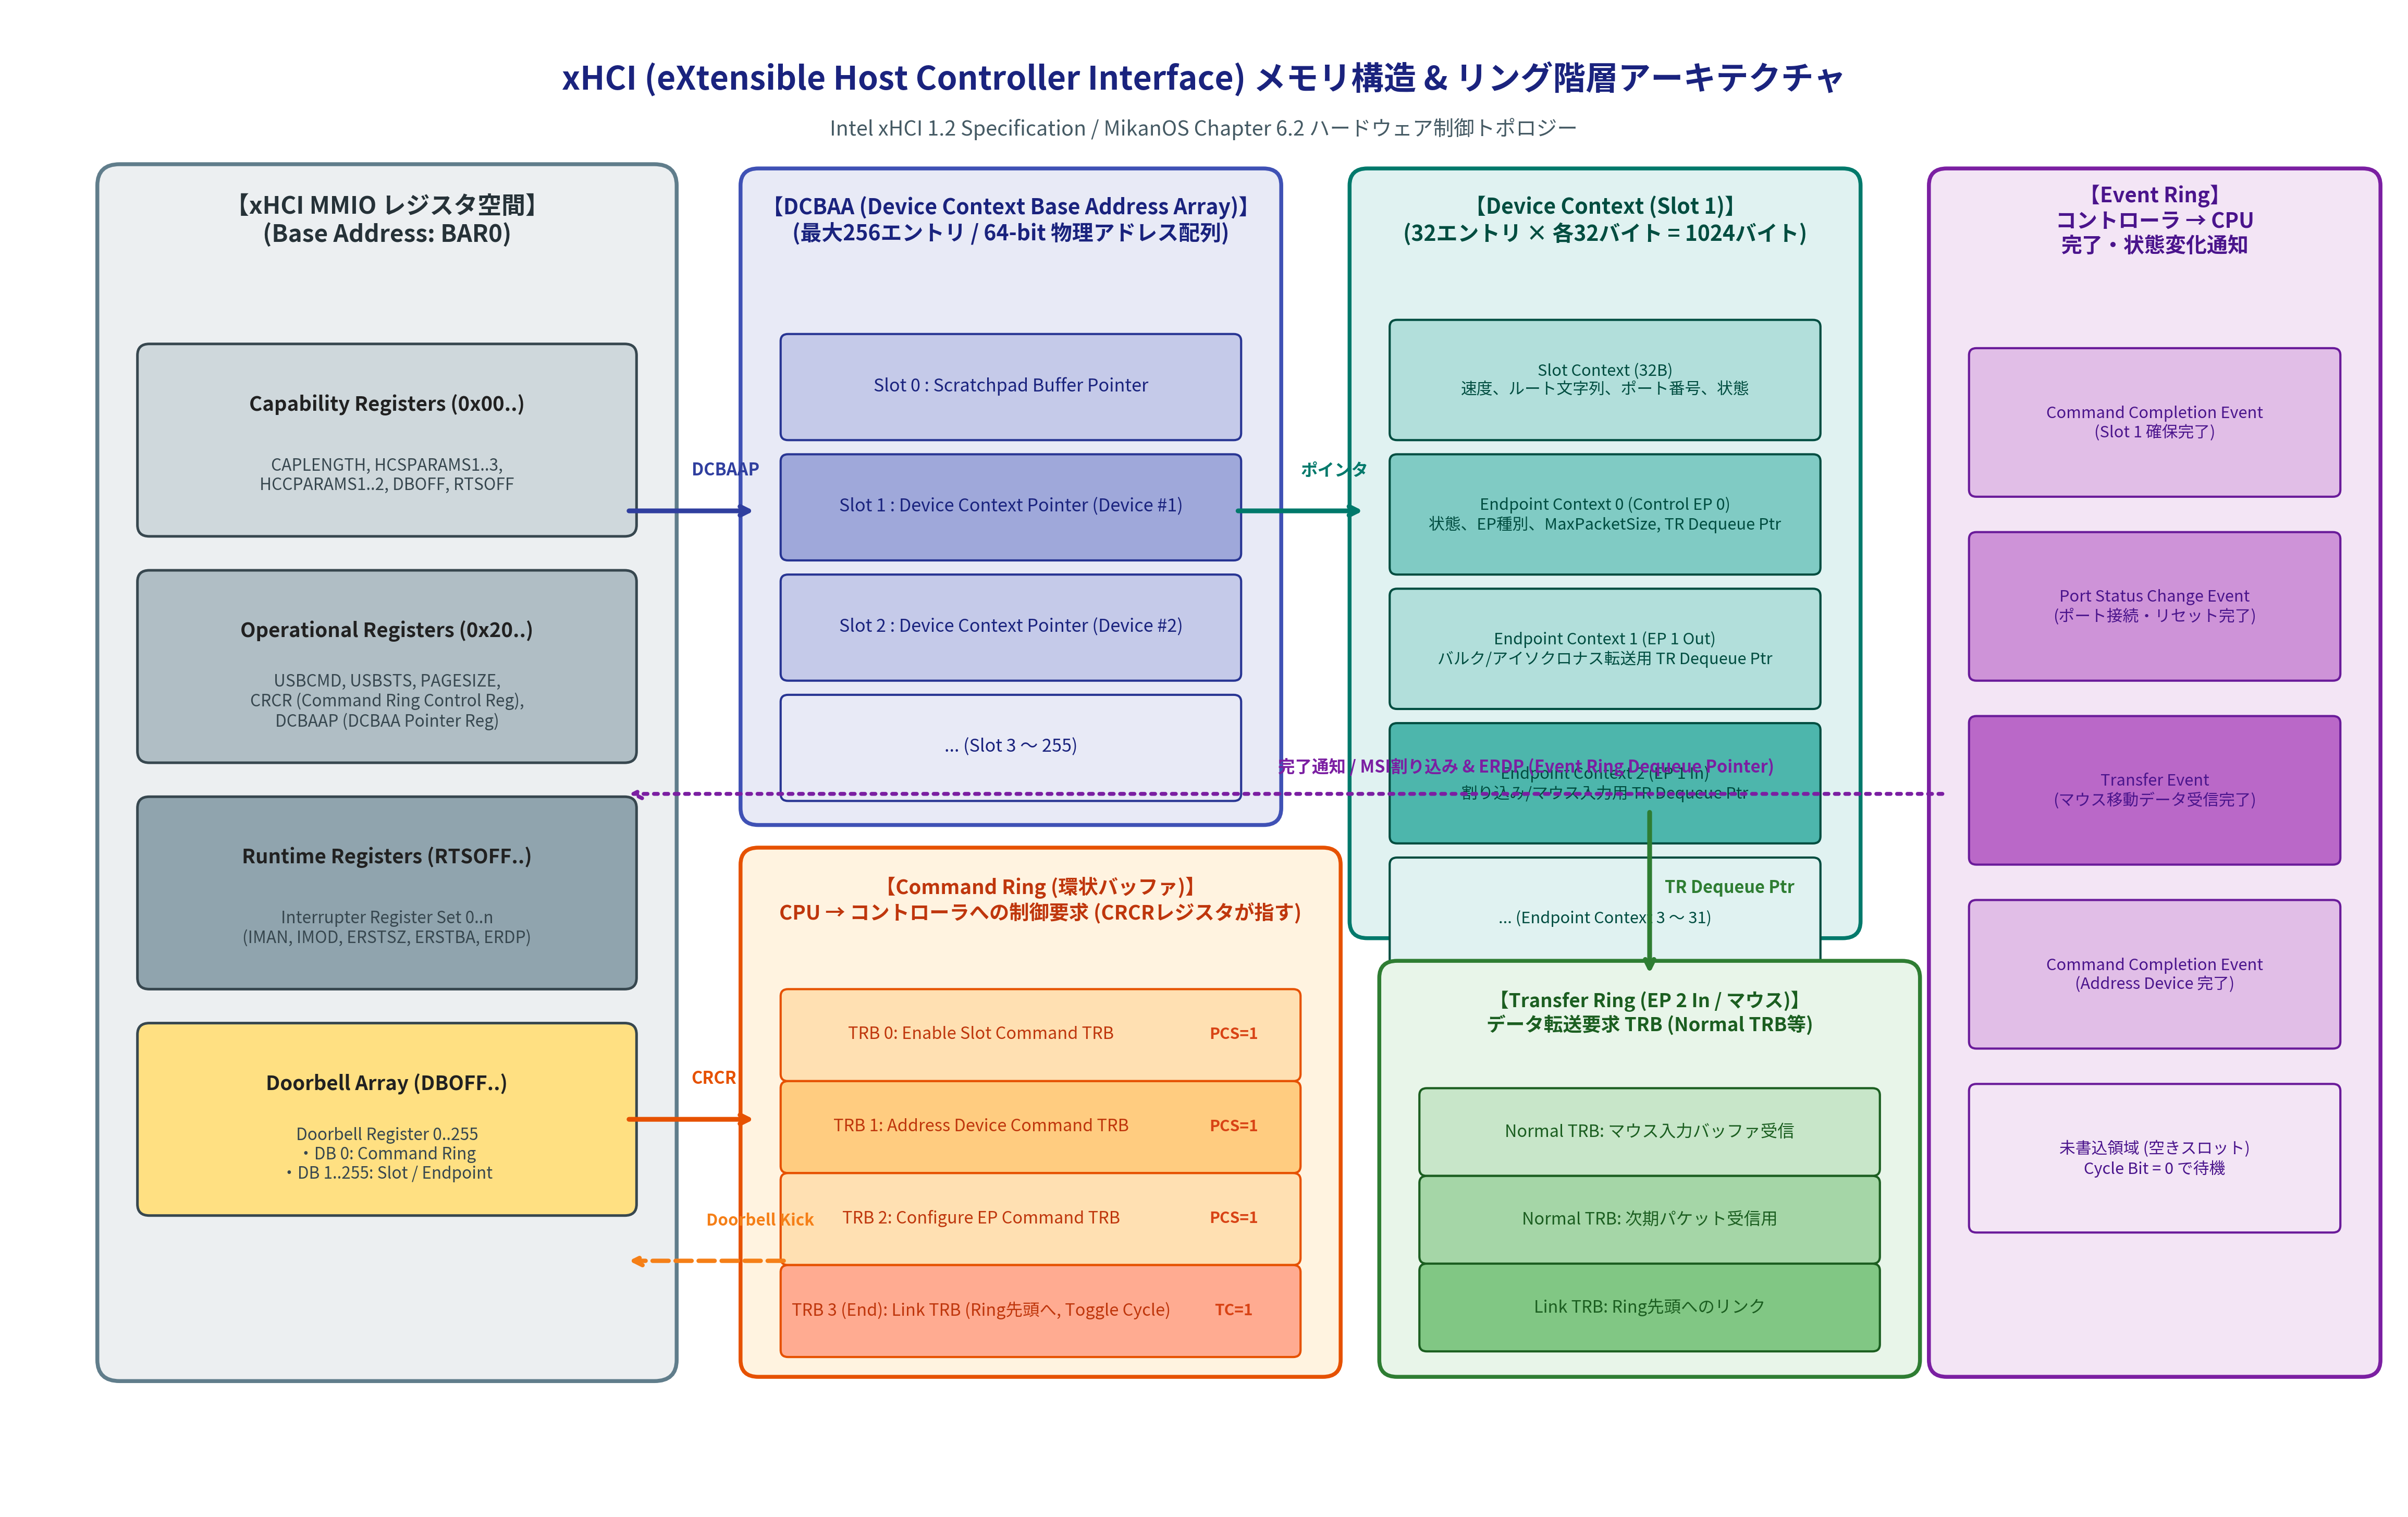

📸 Figure 6.04: TRB バイナリレイアウトと Cycle Bit 遷移モデル (DPI 300)


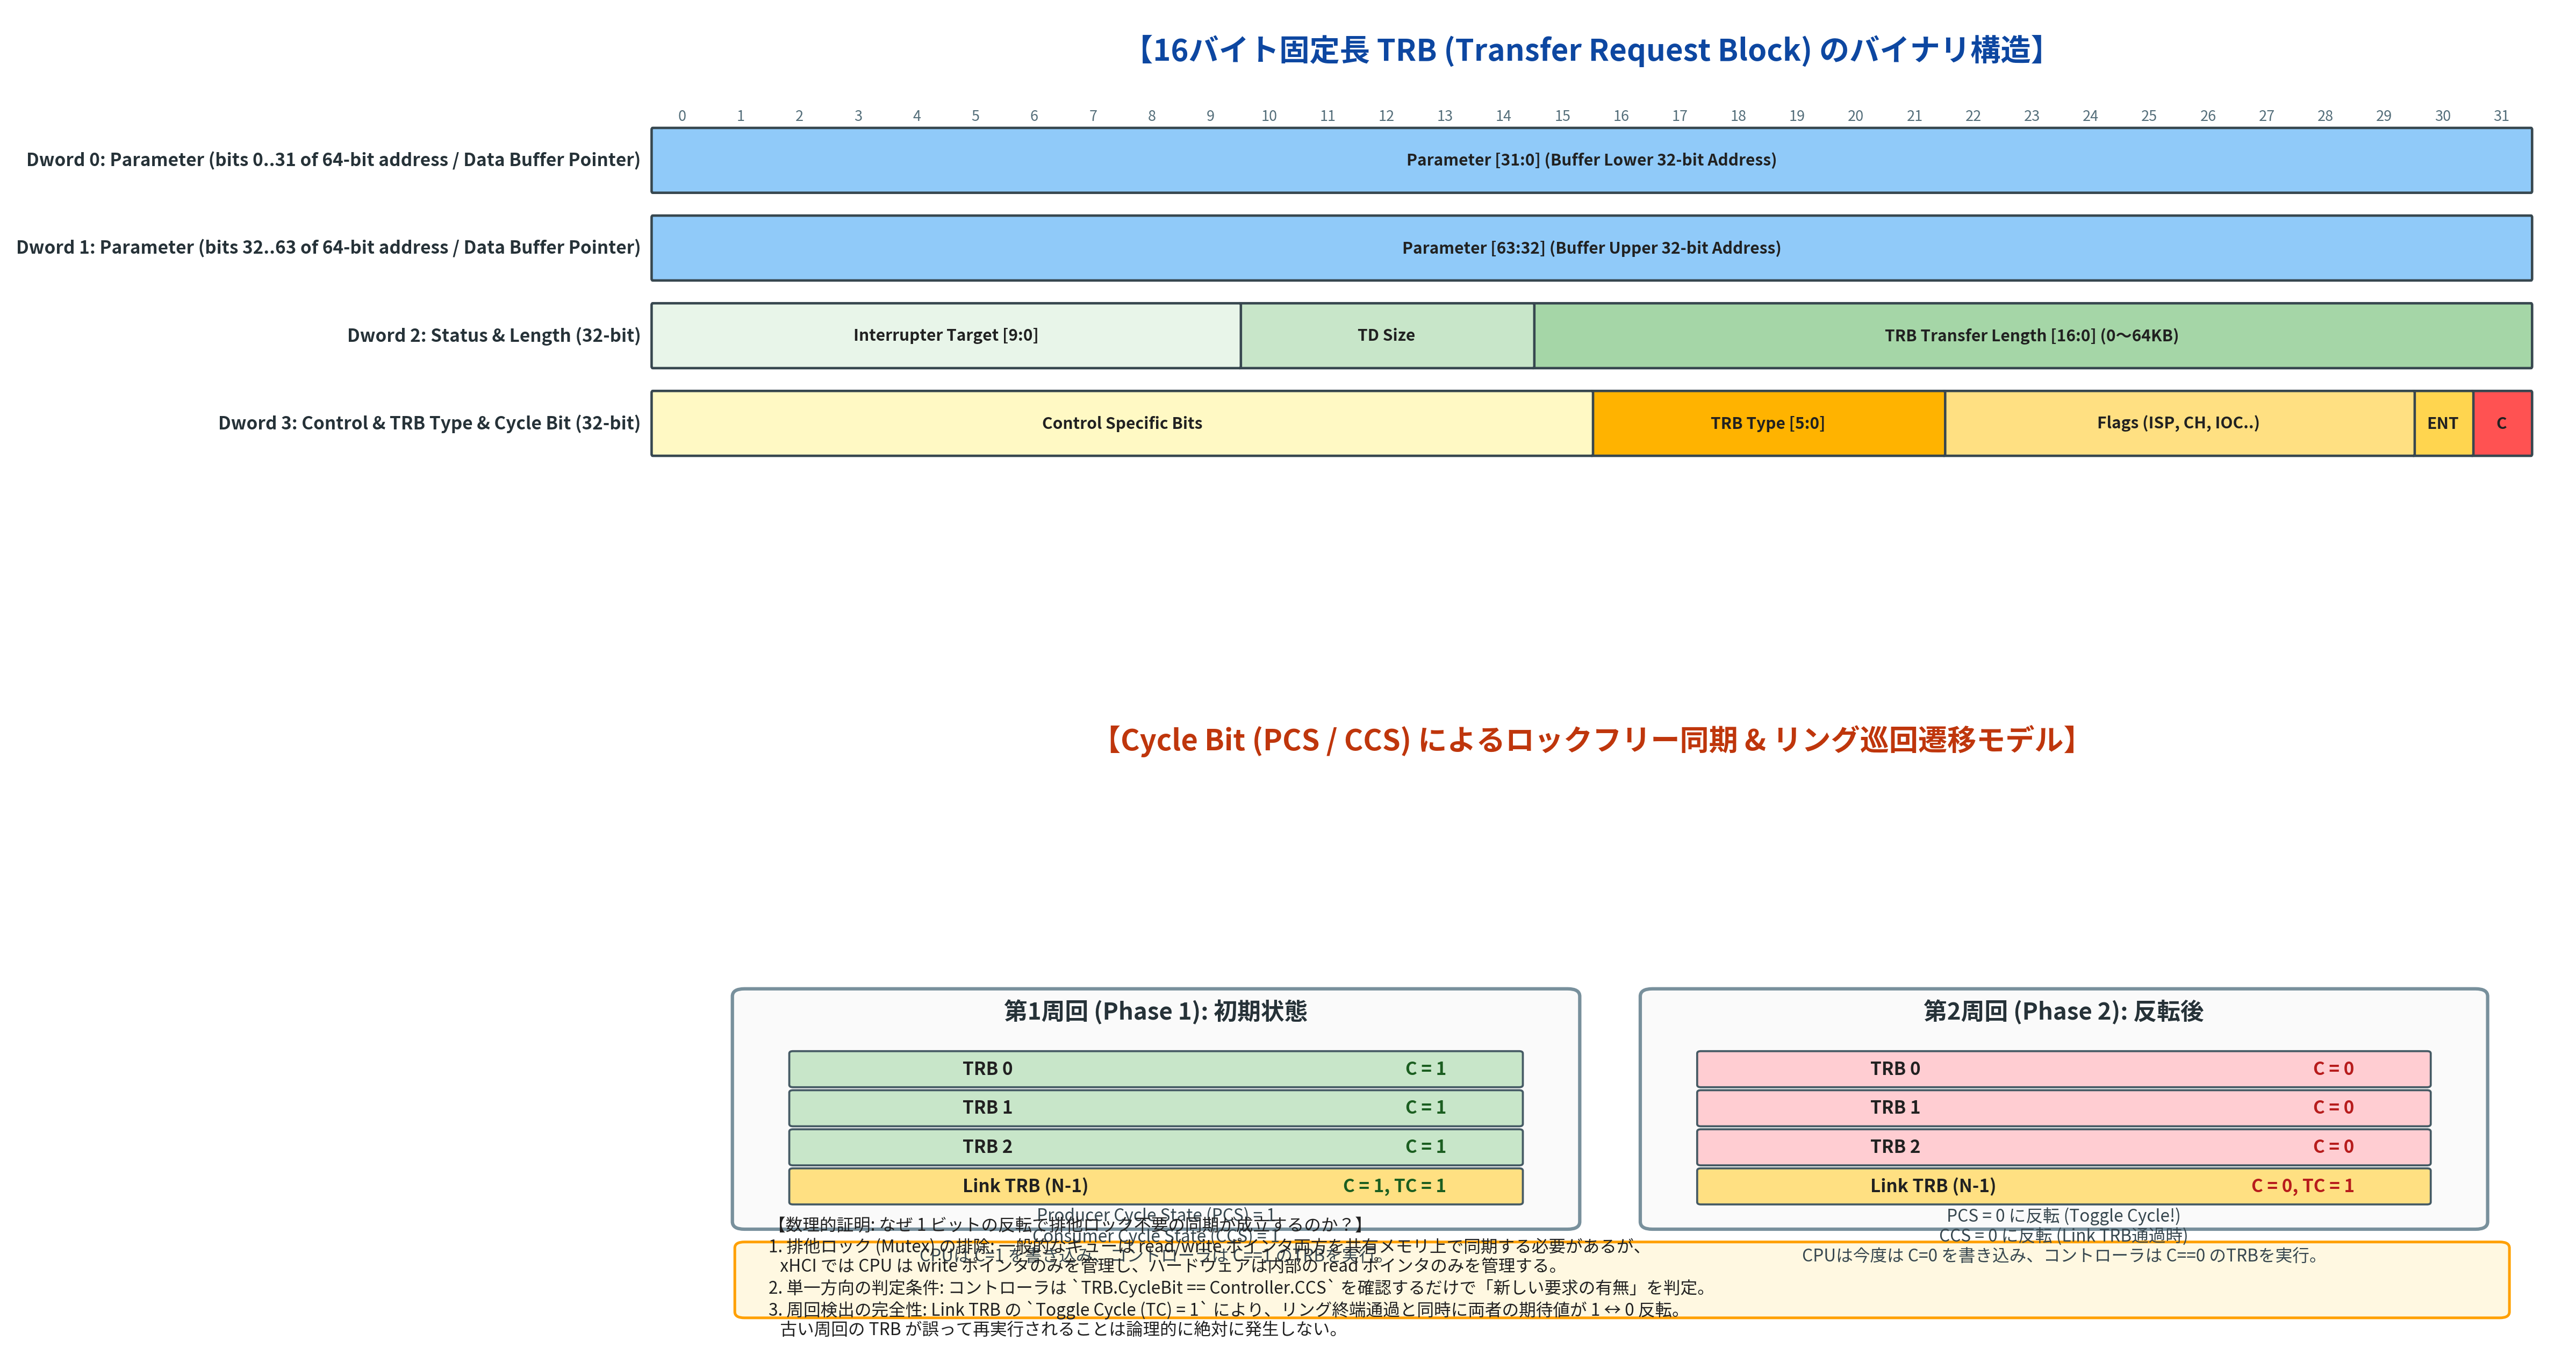

In [3]:
# === Figure 6.03 および Figure 6.04 の生成とインライン表示 ===
import os
from IPython.display import Image, display
from common import (
    plot_fig6_03_xhci_data_structures_and_ring_hierarchy,
    plot_fig6_04_trb_binary_layout_and_cycle_bit_transition,
)

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()
res_dir = os.path.join(repo_root, "6/result")
os.makedirs(res_dir, exist_ok=True)
fig3_path = os.path.join(res_dir, "fig6_03_xhci_data_structures_and_ring_hierarchy.png")
fig4_path = os.path.join(res_dir, "fig6_04_trb_binary_layout_and_cycle_bit_transition.png")

plot_fig6_03_xhci_data_structures_and_ring_hierarchy(fig3_path)
plot_fig6_04_trb_binary_layout_and_cycle_bit_transition(fig4_path)

print("📸 Figure 6.03: xHCI メモリ構造とリング階層モデル (DPI 300)")
display(Image(filename=fig3_path, width=850))

print("📸 Figure 6.04: TRB バイナリレイアウトと Cycle Bit 遷移モデル (DPI 300)")
display(Image(filename=fig4_path, width=850))


## 7. C++20 による xHCI ドライバコア構造の対話型コンパイル & 検証

MikanOS の `usb/xhci` ドライバ（`trb.hpp`, `ring.hpp`, `context.hpp` 等）の中核ロジックを、ホスト環境の C++20（`g++ -std=c++20`）で単体コンパイル・検証可能なスタンドアロンシミュレータ [`src/ch06/xhci_arch_sim.cpp`](../src/ch06/xhci_arch_sim.cpp) として実装しています。

### C++ 実装のハイライト:
```cpp
// 16バイト固定長 TRB の共用体・ビットフィールド定義 (xHCI Spec 1.2)
union TRB {
    std::array<uint32_t, 4> data{};
    struct {
        uint64_t parameter;
        uint32_t status;
        uint32_t cycle_bit : 1;
        uint32_t evaluate_next_trb : 1;
        uint32_t : 8;
        uint32_t trb_type : 6;
        uint32_t control : 16;
    } __attribute__((packed)) bits;
};
static_assert(sizeof(TRB) == 16, "TRB must be exactly 16 bytes");
```

- `static_assert` による厳密な 16バイト / 32バイト / 1024バイト メモリサイズ保証
- Link TRB の自動挿入と `cycle_bit_ = !cycle_bit_` 反転を担う `Ring` クラス
- ドアベルレジスタとイベントリング完了通知パイプライン


In [4]:
# === C++20 スタンドアロン xHCI シミュレータのコンパイルと実行 ===
import os
import subprocess

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == '6' else os.getcwd()
cpp_src = os.path.join(repo_root, "src/ch06/xhci_arch_sim.cpp")
cpp_bin = "/tmp/xhci_arch_sim"

compile_cmd = ["g++", "-std=c++20", "-O2", "-Wall", "-Wextra", cpp_src, "-o", cpp_bin]
print("🛠️ C++20 ソースをコンパイル中:", " ".join(compile_cmd))
subprocess.run(compile_cmd, check=True)

print("\n🚀 --test モードで単体テストスイートを実行中:")
test_res = subprocess.run([cpp_bin, "--test"], capture_output=True, text=True, check=True)
print(test_res.stdout)

print("📋 通常実行時のシステム情報出力:")
info_res = subprocess.run([cpp_bin], capture_output=True, text=True, check=True)
print(info_res.stdout)


🛠️ C++20 ソースをコンパイル中: g++ -std=c++20 -O2 -Wall -Wextra /home/student/Documents/GitHub/study-mikanos/src/ch06/xhci_arch_sim.cpp -o /tmp/xhci_arch_sim



🚀 --test モードで単体テストスイートを実行中:
[TEST] 1. xHCI TRB & Context Memory Layout Verification...
[TEST] 2. Bitfield Alignment & Offset Verification...
[TEST] 3. Ring Push & Link TRB Cycle Bit Toggle Verification...
[TEST] 4. Second Lap Inverted Cycle Bit Verification...
[TEST] 5. Full Controller Doorbell & Event Ring Pipeline...
[SUCCESS] All Chapter 6.2 xHCI architecture simulation tests PASSED!

📋 通常実行時のシステム情報出力:
=== MikanOS Chapter 6.2: USB 3.0 & xHCI Architecture Simulator ===
TRB Size: 16 bytes
Slot Context Size: 32 bytes
Endpoint Context Size: 32 bytes
Device Context Size: 1024 bytes (1024 B)
Pass --test to execute verification suite.



## 8. Python による xHCI 全体アーキテクチャシミュレータの実演

`common.os_sim` に実装された `xHCIArchitectureSimulator` を用いて、実際の OS ブート時における **「Enable Slot Command 投入 → ドアベルキック → ハードウェアによるスロット割り当て → Command Completion Event 受信」** の完全なライフサイクルを対話的にシミュレーションします。


In [5]:
# === xHCI コントローラのコマンド・イベント処理パイプライン実演 ===
from common import xHCIArchitectureSimulator, TRBSim, TRBType

sim = xHCIArchitectureSimulator(max_slots=8, command_ring_size=8, event_ring_size=16)
print(f"コントローラ初期化: 最大スロット数={sim.max_slots}, DCBAA エントリ数={len(sim.dcbaa)}")

# 1. OS が Command Ring に Enable Slot Command (Type 9) を投入
enable_slot_cmd = TRBSim(parameter=0, status=0, cycle_bit=0, trb_type=TRBType.ENABLE_SLOT_COMMAND)
sim.command_ring.push(enable_slot_cmd)
print(f"Command Ring に Enable Slot Command を投入しました (Write Index: {sim.command_ring.write_index})")

# 2. OS が Host Controller Doorbell (Slot 0, Target 0) をキック
doorbell_result = sim.ring_doorbell(slot_id=0, target=0)
print(f"🔔 ドアベル通知結果: {doorbell_result}")

# 3. Event Ring に届いた Command Completion Event の検査
assert len(sim.event_ring) > 0
event = sim.event_ring[0]
print(f"\n📥 受信イベント:")
print(f"   TRB Type: {TRBType(event.trb_type).name} ({event.trb_type})")
print(f"   Cycle Bit: {event.cycle_bit}")
print(f"   割り当てられた Device Slot ID: 1")
print(f"   DCBAA[1] 物理アドレス: 0x{sim.dcbaa[1]:08X}")
print(f"   コントローラ実行履歴: {sim.command_history}")


コントローラ初期化: 最大スロット数=8, DCBAA エントリ数=9
Command Ring に Enable Slot Command を投入しました (Write Index: 1)
🔔 ドアベル通知結果: Controller executed 1 command TRBs

📥 受信イベント:
   TRB Type: COMMAND_COMPLETION_EVENT (33)
   Cycle Bit: 1
   割り当てられた Device Slot ID: 1
   DCBAA[1] 物理アドレス: 0x00010400
   コントローラ実行履歴: ['Processed EnableSlotCommand -> Allocated Slot ID 1']


## 9. コラム: なぜ MikanOS は USB ドライバを自作・ポーリング方式で動かすのか？

### コラム 6.1: ポーリング vs 割り込み（第7章への布石）
USB マウスから座標データを取得するには、デバイスからのデータを定期的に取得する必要があります。本章（第6章）の MikanOS では、カーネルのメインループ内で毎周回 xHCI コントローラのイベントリングを監視する **ポーリング（*Polling*）方式** を採用しています。

ポーリング方式は CPU が常にコントローラの状態を問い合わせ続けるため、実装が極めて単純でブート初期のデバッグが容易という絶大な利点があります。しかし、マウスが動いていないアイドル時でも CPU が 100% 稼働して電力を浪費し、他の処理を実行できないという重大な欠点があります。

次章（**第7章**）では、ハードウェア側から「データが届いた瞬間だけ CPU に通知する」**割り込み（*Interrupt / MSI*）** 機構を構築し、イベント駆動型の洗練された OS アーキテクチャへと進化させます。

---

### コラム 6.2: xHCI 仕様書の難解さと、MikanOS における実用最小限サブセット実装
xHCI の公式仕様書（*xHCI Specification Rev 1.2*）は **約800ページ** に及ぶ長大かつ難解な文書です。あらゆる USB 機器（USBハブ、Webカメラ、外部GPU、USBオーディオ、マスストレージ等）や電源管理（Link Power Management）、仮想化を網羅しているため、その全機能を愚直に実装しようとすると数万行のコードが必要になります。

内田公太氏の MikanOS では、教育用 OS としての明快さを最優先し、**「USB マウスおよび USB キーボードを動かすために真に必要な機能のみ」** を見事に抽出した洗練されたクラスライブラリ（`usb::xhci::Controller`, `Device`, `Ring` 等）を構築しています。この「必要最小限のエッセンスを抽出する設計力」こそが、自作 OS 開発における最大の知恵です。


## 10. 第6章 6.2節の総括と次節（6.3 PCIデバイスの探索）への展望

本節では、MikanOS が USB マウスから入力を受け取るための理論的バックボーンである **USB 3.0 / xHCI アーキテクチャ** を網羅的に学習しました：

- **ホストコントローラの統一**: UHCI/OHCI/EHCI のコンパニオン構成の歴史的課題と xHCI による統一
- **USB 論理階層**: Device → Configuration → Interface → Endpoint のツリー構造と4大転送方式
- **中核データ構造**: DCBAA（256エントリポインタ）、Slot Context / Endpoint Context の 32バイト構造
- **TRB バイナリ仕様**: 16バイト固定長パケットと 4つの Dword 配置
- **Cycle Bit ロックフリー同期**: 1ビットの PCS/CCS 反転と Link TRB による排他ロック不要のリング周回数理
- **制御フロー**: Command Ring への投入 → Doorbell キック → Event Ring への完了通知

---

### 次節への予告: 第6章 6.3節「PCIデバイスの探索」
xHCI コントローラのメモリ構造と制御手順を完全に理解した今、残る最初の課題は **「PC のマザーボード上に存在する xHCI コントローラの実体を、プログラムからどうやって発見し、その MMIO レジスタのベースアドレス（BAR0）を取得するのか？」** です。

次節（**第6章 6.3節 / `osbook_day06b`**）では、x86 CPU の I/O ポート `0xCF8`（`CONFIG_ADDRESS`）と `0xCFC`（`CONFIG_DATA`）に対して `in` / `out` アセンブリ命令を実行し、マザーボード上のすべての **PCI バス・デバイス・ファンクション** を走査して xHCI コントローラを自動特定するアルゴリズムを実装します！
